# 01 — Data exploration and preparation

**Research question.** *Do climate-related disasters (floods, storms, droughts, heatwaves, wildfires) that hit a country in a given year reduce its economic growth, and by how much?*

**Learning task.** Supervised regression: predict the annual real GDP growth (%) of country $i$ in year $t$ from its exposure to climate disasters (years $t$ and $t-1$) and macroeconomic control variables.

**Success criteria.** (i) The model must beat naive baselines (mean, persistence) on a test period *later* than the training period; (ii) adding the disaster variables must lower the out-of-sample error compared with a controls-only model — this is the direct test of the question; (iii) the estimated effects must be stable (bootstrap confidence intervals).

**Data (Kaggle).**
| Dataset | Kaggle URL | Original source | Content |
|---|---|---|---|
| Natural disasters 1900–2021 | https://www.kaggle.com/datasets/brsdincer/all-natural-disasters-19002021-eosdis | EM-DAT (CRED, UCLouvain) | 1 row = 1 disaster: country, year, type, deaths, people affected, damages (thousand USD) |
| World GDP | https://www.kaggle.com/datasets/zgrcemta/world-gdpgdp-gdp-per-capita-and-annual-growths | World Bank (WDI) | Current GDP, GDP per capita, real GDP growth, 1960–2020 |

In [1]:
import os, sys, time, warnings
sys.path.insert(0, os.path.abspath(".."))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # metrics are allowed
from src import data_prep as dp
from src.plot_style import *
setup()
SEED = 42
np.random.seed(SEED)
pd.set_option("display.precision", 3)
import seaborn as sns

## 1. Raw EM-DAT data

In [2]:
dis = dp.load_disasters()
print(dis.shape)
dis[["Year", "Country", "ISO", "Disaster Type", "Total Deaths", "Total Affected", dp.DMG_COL]].sample(5, random_state=SEED)

(14644, 47)


,Year,Country,ISO,Disaster Type,Total Deaths,Total Affected,Total Damages ('000 US$)
4965,1997,Russian Federation (the),RUS,Wildfire,14.0,NaN,NaN
12449,2016,Korea (the Democratic People's Republic of),PRK,Flood,538.0,667715.0,61000.0
6363,2002,Chile,CHL,Extreme temperature,NaN,25000.0,NaN
8882,2006,Chad,TCD,Epidemic,20.0,216.0,NaN
8294,2006,China,CHN,Flood,42.0,10009.0,11000.0


In [3]:
dis["group"] = dis["Disaster Type"].map(dp.CLIMATE_GROUPS)
dis.loc[dis["Disaster Type"].isin(dp.GEO_TYPES), "group"] = "geo"
print(dis["group"].value_counts(dropna=False))   # NaN = epidemics, insects... excluded

group
hydro      5987
meteo      4005
NaN        2115
geo        1400
climato    1137
Name: count, dtype: int64


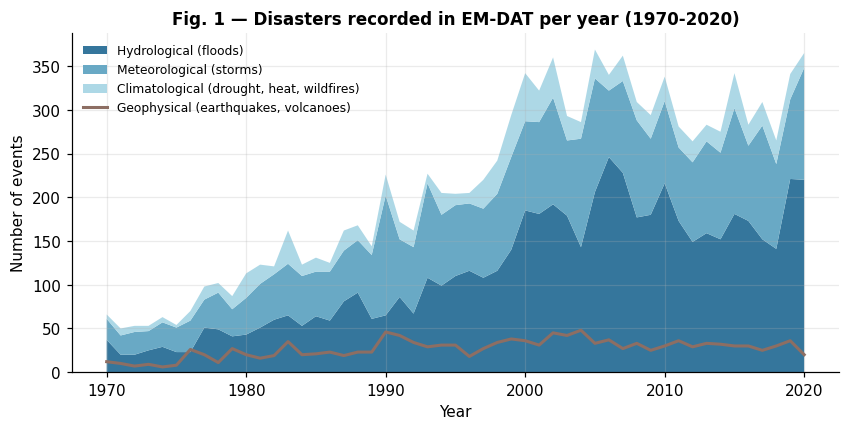

In [4]:
labels = {"hydro": "Hydrological (floods)", "meteo": "Meteorological (storms)",
          "climato": "Climatological (drought, heat, wildfires)", "geo": "Geophysical (earthquakes, volcanoes)"}
cnt = dis[dis.group.notna()].pivot_table(index="Year", columns="group", values="Dis No", aggfunc="count").fillna(0)
cnt = cnt[cnt.index <= 2020]
fig, ax = plt.subplots(figsize=(9, 4))
ax.stackplot(cnt.index, cnt["hydro"], cnt["meteo"], cnt["climato"],
             labels=[labels[g] for g in ["hydro", "meteo", "climato"]],
             colors=["#2a6f97", "#61a5c2", "#a9d6e5"], alpha=0.95)
ax.plot(cnt.index, cnt["geo"], color=C_GEO, lw=2, label=labels["geo"])
ax.set(title="Fig. 1 — Disasters recorded in EM-DAT per year (1970-2020)",
       xlabel="Year", ylabel="Number of events")
ax.legend(loc="upper left", fontsize=8)
save(fig, "fig01_disasters_per_year.png"); plt.show()

The number of **climate** events grows about fivefold between 1970 and 2000, while **geophysical** disasters stay flat. Part of the increase is real (warming, urbanisation of exposed areas), but part of it comes from better recording: this is one of the main biases of the dataset, discussed in the report.

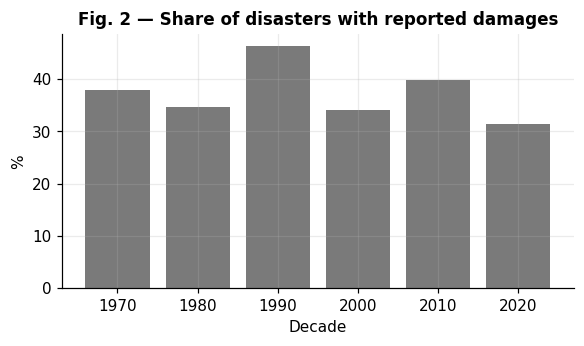

decade
1970    37.9
1980    34.8
1990    46.3
2000    34.1
2010    39.9
2020    31.5
Name: Total Damages ('000 US$), dtype: float64

In [5]:
dis["decade"] = (dis.Year // 10) * 10
miss = dis[dis.group.notna()].groupby("decade")[dp.DMG_COL].apply(lambda s: s.notna().mean() * 100)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(miss.index.astype(str), miss.values, color=C_NEUTRAL)
ax.set(title="Fig. 2 — Share of disasters with reported damages", xlabel="Decade", ylabel="%")
save(fig, "fig02_damage_reporting.png"); plt.show()
miss.round(1)

Only ~30–40 % of disasters have a reported damage amount. **Missing-value treatment**: a missing amount counts as 0 in the country-year aggregate. This is a strong assumption (it underestimates damages, especially in poor countries), which we partly offset with variables that are always reported: number of events, deaths and people affected relative to population.

## 2. Building the country-year panel
`src/data_prep.py`:
1. aggregates disasters by (ISO country, year): damages, deaths, people affected, number of events per group;
2. merges with the World Bank data; country-years without a disaster get 0;
3. scales by country size: damages as **% of GDP**, deaths **per million inhabitants**, people affected as **% of population** (population = GDP / GDP per capita);
4. applies $\log(1+x)$ to the highly skewed variables;
5. creates the lags ($t-1$), checking that the previous year really exists;
6. adds the world growth of the year (`WLD` row) as a control for the global cycle.

In [6]:
panel = dp.build_panel()
os.makedirs("../data/processed", exist_ok=True)
panel.to_csv("../data/processed/panel.csv", index=False)
print(f"{len(panel)} observations, {panel.ISO.nunique()} countries, {panel.year.min()}-{panel.year.max()}")
panel[dp.FEATURES + [dp.TARGET]].describe().T[["mean", "std", "min", "50%", "max"]]

8093 observations, 201 countries, 1971-2020


,mean,std,min,50%,max
log_dmg_climate_pct,0.091,0.387,0.000,0.000,5.639
log_dmg_climate_pct_lag1,0.092,0.393,0.000,0.000,5.639
log_deaths_climate_pm,0.382,0.841,0.000,0.000,8.970
log_affected_climate_pct,0.281,0.725,0.000,0.000,4.807
n_hydro,0.679,1.518,0.000,0.000,26.000
n_meteo,0.450,1.505,0.000,0.000,27.000
n_climato,0.127,0.428,0.000,0.000,9.000
log_dmg_geo_pct,0.015,0.169,0.000,0.000,4.574
growth_lag1,3.691,6.215,-64.047,3.771,149.973
log_gdppc_lag1,7.809,1.641,2.998,7.723,11.724


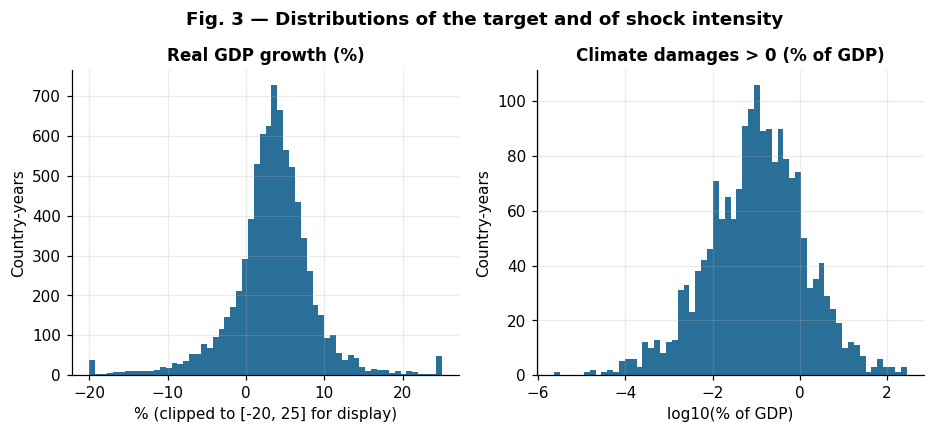

Country-years with climate damages > 0: 22.0%
... > 1 % of GDP: 3.7%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(panel.gdp_growth.clip(-20, 25), bins=60, color=C_SCRATCH)
axes[0].set(title="Real GDP growth (%)", xlabel="% (clipped to [-20, 25] for display)", ylabel="Country-years")
pos = panel.loc[panel.dmg_climate_pct > 0, "dmg_climate_pct"]
axes[1].hist(np.log10(pos), bins=60, color=C_CLIMATE)
axes[1].set(title="Climate damages > 0 (% of GDP)", xlabel="log10(% of GDP)", ylabel="Country-years")
fig.suptitle("Fig. 3 — Distributions of the target and of shock intensity", fontweight="bold", y=1.03)
save(fig, "fig03_distributions.png"); plt.show()
print(f"Country-years with climate damages > 0: {(panel.dmg_climate_pct > 0).mean():.1%}")
print(f"... > 1 % of GDP: {(panel.dmg_climate_pct > 1).mean():.1%}")

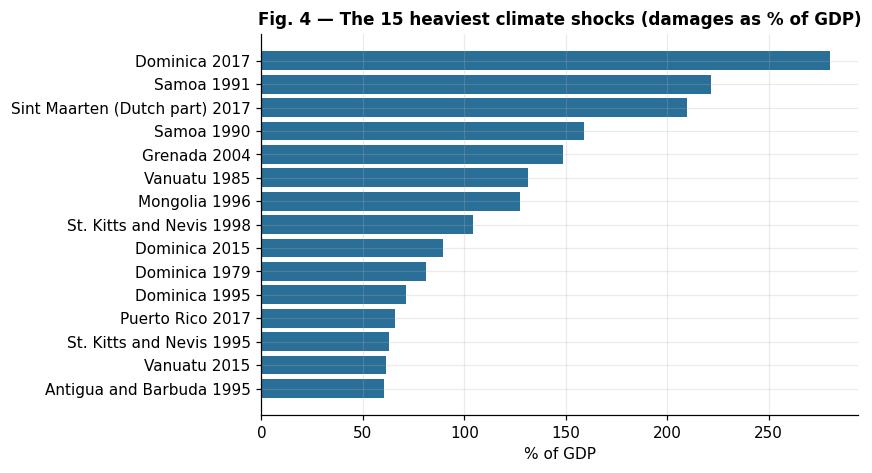

In [8]:
top = panel.nlargest(15, "dmg_climate_pct")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top.country + " " + top.year.astype(str), top.dmg_climate_pct, color=C_CLIMATE)
ax.invert_yaxis()
ax.set(title="Fig. 4 — The 15 heaviest climate shocks (damages as % of GDP)", xlabel="% of GDP")
save(fig, "fig04_top_shocks.png"); plt.show()

The heaviest shocks almost all hit **small island states** (Caribbean, Pacific) struck by cyclones: a single hurricane can destroy more than the country's annual GDP (Dominica 2017, Hurricane Maria: 280 %).

## 3. Raw relationship between shocks and growth

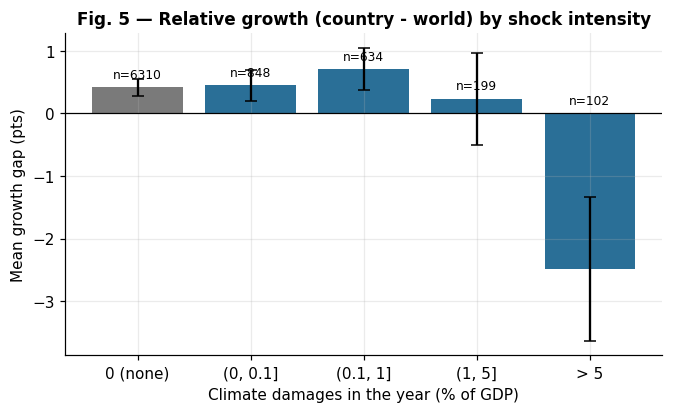

,mean,std,count,ci
bucket,,,,
0 (none),0.418,5.627,6310,0.139
"(0, 0.1]",0.447,3.623,848,0.244
"(0.1, 1]",0.705,4.362,634,0.340
"(1, 5]",0.234,5.281,199,0.734
> 5,-2.480,5.924,102,1.150


In [9]:
df = panel.copy()
df["gap"] = df.gdp_growth.clip(-30, 30) - df.world_growth          # growth relative to the global cycle
bins = [-np.inf, 0, 0.1, 1, 5, np.inf]
names = ["0 (none)", "(0, 0.1]", "(0.1, 1]", "(1, 5]", "> 5"]
df["bucket"] = pd.cut(df.dmg_climate_pct, bins=bins, labels=names)
g = df.groupby("bucket", observed=True)["gap"].agg(["mean", "std", "count"])
g["ci"] = 1.96 * g["std"] / np.sqrt(g["count"])
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(g.index.astype(str), g["mean"], yerr=g["ci"], capsize=4,
       color=[C_NEUTRAL] + [C_CLIMATE] * 4)
for i, (m, n) in enumerate(zip(g["mean"], g["count"])):
    ax.text(i, 0.15 if m < 0 else m + 0.15, f"n={n}", ha="center", fontsize=8)
ax.axhline(0, color="k", lw=0.8)
ax.set(title="Fig. 5 — Relative growth (country - world) by shock intensity",
       xlabel="Climate damages in the year (% of GDP)", ylabel="Mean growth gap (pts)")
save(fig, "fig05_growth_by_bucket.png"); plt.show()
g

### Event study
For each major shock (damages ≥ 1 % of GDP), we track the country's growth deviation from its own long-run mean from $t-2$ to $t+3$. This purely descriptive chart motivates including a lagged effect ($t-1$) in the models.

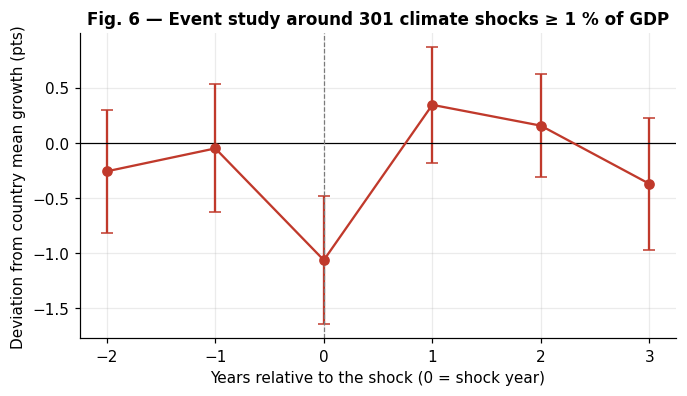

,k,mean,ci,n
0,-2,-0.261,0.559,290
1,-1,-0.052,0.582,296
2,0,-1.067,0.583,301
3,1,0.343,0.524,295
4,2,0.154,0.468,292
5,3,-0.374,0.602,289


In [10]:
df["dev"] = df.gdp_growth.clip(-30, 30) - df.groupby("ISO").gdp_growth.transform(lambda s: s.clip(-30, 30).mean())
idx = df.set_index(["ISO", "year"])["dev"]
events = df.loc[df.dmg_climate_pct >= 1, ["ISO", "year"]]
offsets = range(-2, 4)
rows = []
for k in offsets:
    vals = [idx.get((iso, y + k), np.nan) for iso, y in events.itertuples(index=False)]
    vals = np.array(vals, float); vals = vals[~np.isnan(vals)]
    rows.append((k, vals.mean(), 1.96 * vals.std(ddof=1) / np.sqrt(len(vals)), len(vals)))
es = pd.DataFrame(rows, columns=["k", "mean", "ci", "n"])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.errorbar(es.k, es["mean"], yerr=es["ci"], marker="o", color=C_ACCENT, capsize=4)
ax.axhline(0, color="k", lw=0.8); ax.axvline(0, color=C_NEUTRAL, ls="--", lw=0.8)
ax.set(title=f"Fig. 6 — Event study around {len(events)} climate shocks ≥ 1 % of GDP",
       xlabel="Years relative to the shock (0 = shock year)", ylabel="Deviation from country mean growth (pts)")
save(fig, "fig06_event_study.png"); plt.show()
es

## 4. Chronological split and leakage prevention

* **Train**: 1971–2005 · **Validation**: 2006–2012 (hyperparameter selection) · **Test**: 2013–2019 (final evaluation, used only once) · **2020**: COVID year, kept apart as a *stress test* (an out-of-distribution global shock).
* The split is **chronological**, not random: a random split would put future years in the training set and overstate performance (growth series are autocorrelated).
* The **winsorization** bounds (1st and 99th percentiles of growth, to neutralise wars and oil booms: −64 % to +150 %) and the **standardization** parameters (mean, standard deviation) are estimated **on the training set only**, then applied to the other samples.
* Lags ($t-1$) only use information available before the predicted year. World growth in year $t$ is a contemporaneous variable: it is an explanatory control (we are not doing operational forecasting).

train     5174
val       1359
test      1371
stress     189
Name: n, dtype: int64
Winsorization bounds (train): {'gdp_growth': (-13.48, 21.34), 'growth_lag1': (-13.96, 21.8)}


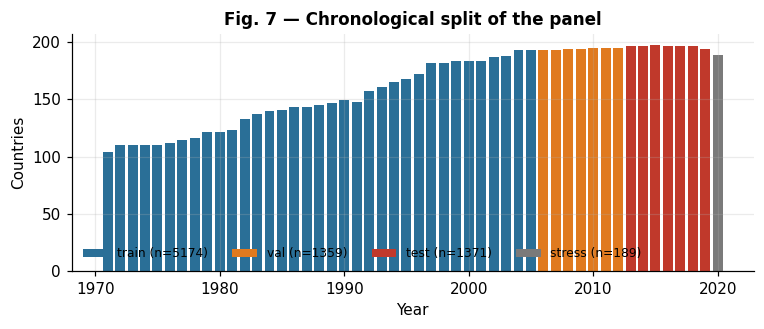

In [11]:
s = dp.make_splits(panel)
sizes = pd.Series({k: len(v) for k, v in s.frames.items()}, name="n")
print(sizes); print("Winsorization bounds (train):", {k: tuple(round(x, 2) for x in v) for k, v in s.clip.items()})
cols = {"train": C_SCRATCH, "val": C_SKLEARN, "test": C_ACCENT, "stress": C_NEUTRAL}
fig, ax = plt.subplots(figsize=(8, 2.8))
for k, f in s.frames.items():
    c = f.year.value_counts().sort_index(); ax.bar(c.index, c.values, color=cols[k], label=f"{k} (n={len(f)})")
ax.set(title="Fig. 7 — Chronological split of the panel", xlabel="Year", ylabel="Countries")
ax.legend(ncol=4, fontsize=8, loc="lower left")
save(fig, "fig07_splits.png"); plt.show()

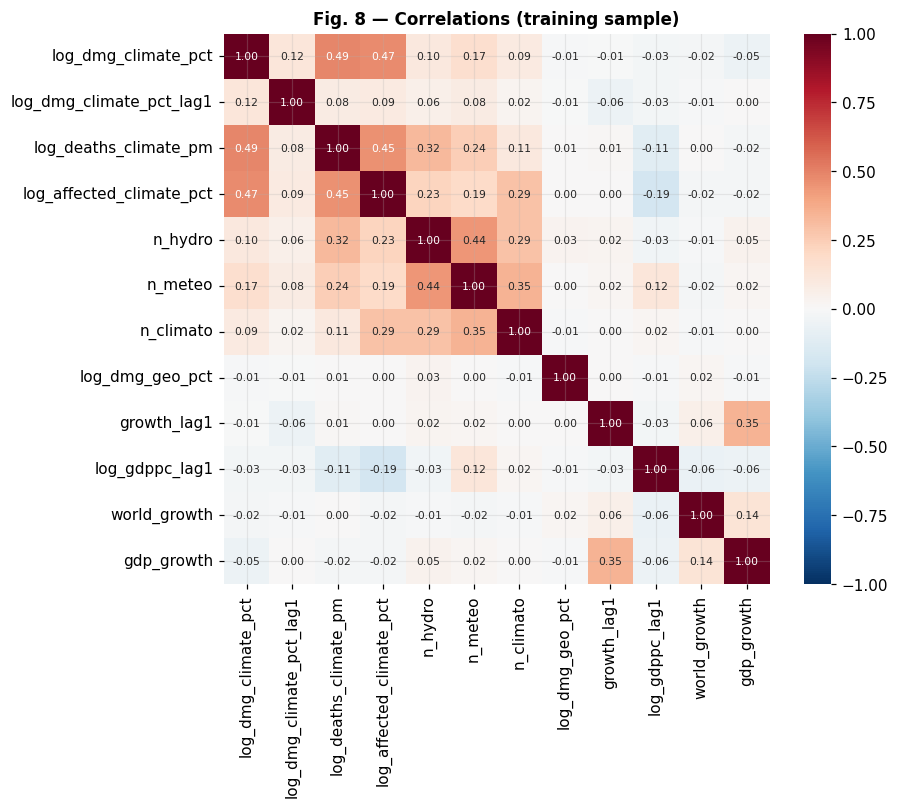

In [12]:
corr = s.frames["train"][dp.FEATURES + [dp.TARGET]].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Fig. 8 — Correlations (training sample)")
save(fig, "fig08_correlations.png"); plt.show()

**Takeaway.** Raw linear correlations between shocks and growth are weak (|ρ| < 0.1): growth depends mostly on its own persistence (`growth_lag1`) and on the global cycle. The disaster variables are correlated with each other (damages / deaths / people affected), which motivates testing a Ridge penalty. We therefore expect a **modest but measurable** predictive gain from adding disasters — which notebooks 02 and 03 quantify.